## 8-2_Classifying_Data_with_a_Linear_Support_Vector_Machines

In [1]:
## 1-1. Import NumPy.

#load the libraries we have been using
import numpy as np

In [2]:
## 1-2. Import pandas.

import pandas as pd

In [3]:
## 1-3. Import matplotlib for visualization.

import matplotlib.pyplot as plt  #Library for visualization

In [4]:
## 1-4. Import scikit-learn datasets.

from sklearn import datasets

In [5]:
## 1-5. Load the Iris dataset.

iris = datasets.load_iris()

In [6]:
## 1-6. Extract features and target labels.

X_w = iris.data[:, :2]  #load the first two features of the iris data
y_w = iris.target         #load the target of the iris data

In [7]:
## 1-7. Select the first two Iris classes.

#select only the first two classes for both the feature set and target set
#the first two classes of the iris dataset: Setosa (0), Versicolour (1)

X = X_w[y_w < 2]
y = y_w[y_w < 2]

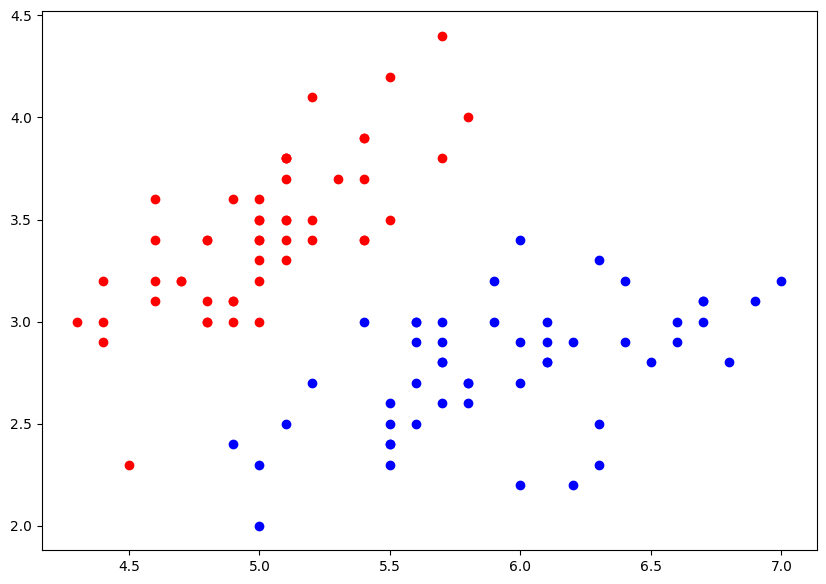

In [8]:
## 2. Visualize the two Iris classes using a scatter plot.

X_0 = X[y == 0]
X_1 = X[y == 1]

#to visualize within IPython
%matplotlib inline

plt.figure(figsize=(10,7))   #change figure-size for easier viewing
plt.scatter(X_0[:,0],X_0[:,1], color = 'red')
plt.scatter(X_1[:,0],X_1[:,1], color = 'blue')

In [9]:
## 3. Split the dataset into training and test sets.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7,stratify=y)

In [ ]:
## 4. Train a linear SVM classifier and make predictions.

from sklearn.svm import SVC

svm_inst = SVC(kernel='linear')
svm_inst.fit(X_train,y_train)
y_pred = svm_inst.predict(X_test)


In [ ]:
## 5. Evaluate the SVM classifier using accuracy.

from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)


1.0

Text(0.5, 1.0, 'Linearly-separated classes')

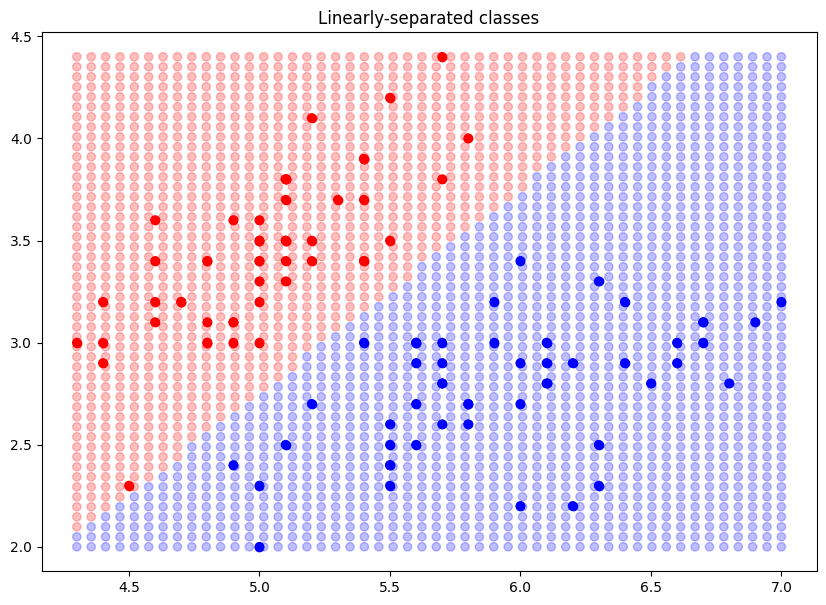

In [14]:
## 6. Visualize the classification regions of the linear SVM.

from itertools import product

#Minima and maxima of both features
xmin, xmax = np.percentile(X[:, 0], [0, 100])
ymin, ymax = np.percentile(X[:, 1], [0, 100])

#Grid/Cartesian product with itertools.product
test_points = np.array([[xx, yy] for xx, yy in product(np.linspace(xmin, xmax), np.linspace(ymin, ymax))])

#Predictions on the grid
test_preds = svm_inst.predict(test_points)

X_0 = X[y == 0]
X_1 = X[y == 1]

%matplotlib inline
plt.figure(figsize=(10,7))   #change figure-size for easier viewing
plt.scatter(X_0[:,0], X_0[:,1], color = 'red')
plt.scatter(X_1[:,0], X_1[:,1], color = 'blue')

colors = np.array(['r', 'b'])
plt.scatter(test_points[:, 0], test_points[:, 1], color=colors[test_preds], alpha=0.25)
plt.scatter(X[:, 0], X[:, 1], color=colors[y])
plt.title("Linearly-separated classes")


In [ ]:
## 7. Inspect the coefficients of the linear SVM.

svm_inst.coef_

array([[ 2.22246001, -2.2213921 ]])

In [18]:
## 8. Inspect the intercept of the linear SVM.

svm_inst.intercept_

array([-5.00384439])

In [19]:
## 9. Display the trained SVM model.

svm_inst

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
